**Lab03_Data_Quality_EDA_Preprocessing.ipnb**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make graphs look clean and modern
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# If your notebook is inside the notebooks/ folder:
df = pd.read_csv("../data/processed/olist_orders_abt.csv")

# If that gives an error, try:
# df = pd.read_csv("data/processed/olist_orders_abt.csv")

df.head()

,order_id,customer_id,customer_unique_id,customer_city,customer_state,order_status,order_year,order_month,order_day,order_day_of_week,...,total_payment_value,max_payment_installments,payment_types_count,dominant_payment_type,total_items,total_price,total_freight,unique_products,unique_sellers,main_product_category
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,delivered,2017,10,2,0,...,38.71,1.0,2.0,voucher,1.0,29.99,8.72,1.0,1.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,barreiras,BA,delivered,2018,7,24,1,...,141.46,1.0,1.0,boleto,1.0,118.70,22.76,1.0,1.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,delivered,2018,8,8,2,...,179.12,3.0,1.0,credit_card,1.0,159.90,19.22,1.0,1.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,delivered,2017,11,18,5,...,72.20,1.0,1.0,credit_card,1.0,45.00,27.20,1.0,1.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,delivered,2018,2,13,1,...,28.62,1.0,1.0,credit_card,1.0,19.90,8.72,1.0,1.0,stationery


In [3]:
print("Dataset Shape (Rows, Columns):", df.shape)

Dataset Shape (Rows, Columns): (99441, 29)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  99441 non-null  str    
 1   customer_id               99441 non-null  str    
 2   customer_unique_id        99441 non-null  str    
 3   customer_city             99441 non-null  str    
 4   customer_state            99441 non-null  str    
 5   order_status              99441 non-null  str    
 6   order_year                99441 non-null  int64  
 7   order_month               99441 non-null  int64  
 8   order_day                 99441 non-null  int64  
 9   order_day_of_week         99441 non-null  int64  
 10  order_hour                99441 non-null  int64  
 11  delivery_days             96476 non-null  float64
 12  estimated_delivery_days   99441 non-null  int64  
 13  delivery_delay_days       96476 non-null  float64
 14  is_late_delivery 

In [5]:
df.describe()

,order_year,order_month,order_day,order_day_of_week,order_hour,delivery_days,estimated_delivery_days,delivery_delay_days,is_late_delivery,review_score,...,review_comment_count,has_review_comment,total_payment_value,max_payment_installments,payment_types_count,total_items,total_price,total_freight,unique_products,unique_sellers
count,99441.000000,99441.000000,99441.000000,99441.000000,99441.000000,96476.000000,99441.000000,96476.000000,99441.000000,98673.000000,...,98673.000000,98673.000000,99440.000000,99440.000000,99440.000000,98666.000000,98666.000000,98666.000000,98666.000000,98666.000000
mean,2017.539838,6.032220,15.505948,2.755735,14.770829,12.094086,23.403958,-11.876881,0.065717,4.086793,...,0.415281,0.413852,160.990267,2.930521,1.022586,1.141731,137.754076,22.823562,1.038098,1.013622
std,0.505007,3.232999,8.667298,1.966495,5.326800,9.551746,8.829562,10.183854,0.247789,1.346274,...,0.495685,0.492525,221.951257,2.715685,0.148582,0.538452,210.645145,21.650909,0.226456,0.122297
min,2016.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,-147.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.850000,0.000000,1.000000,1.000000
25%,2017.000000,3.000000,8.000000,1.000000,11.000000,6.000000,18.000000,-17.000000,0.000000,4.000000,...,0.000000,0.000000,62.010000,1.000000,1.000000,1.000000,45.900000,13.850000,1.000000,1.000000
50%,2018.000000,6.000000,15.000000,3.000000,15.000000,10.000000,23.000000,-12.000000,0.000000,5.000000,...,0.000000,0.000000,105.290000,2.000000,1.000000,1.000000,86.900000,17.170000,1.000000,1.000000
75%,2018.000000,8.000000,23.000000,4.000000,19.000000,15.000000,28.000000,-7.000000,0.000000,5.000000,...,1.000000,1.000000,176.970000,4.000000,1.000000,1.000000,149.900000,24.040000,1.000000,1.000000
max,2018.000000,12.000000,31.000000,6.000000,23.000000,209.000000,155.000000,188.000000,1.000000,5.000000,...,3.000000,1.000000,13664.080000,24.000000,2.000000,21.000000,13440.000000,1794.960000,8.000000,5.000000


In [6]:
# Function to keep only columns that actually exist in your dataset
def keep_existing_columns(dataframe, columns):
    return [col for col in columns if col in dataframe.columns]

nominal_columns = [
    "customer_state", "customer_city", "main_product_category", 
    "dominant_payment_type", "order_status"
]
ordinal_columns = ["review_score"]
interval_columns = ["order_hour", "order_month", "order_day_of_week"]
ratio_columns = [
    "total_payment_value", "total_price", "total_freight", 
    "delivery_days", "estimated_delivery_days", "delivery_delay_days", 
    "total_items", "unique_products", "unique_sellers"
]

nominal_columns = keep_existing_columns(df, nominal_columns)
ordinal_columns = keep_existing_columns(df, ordinal_columns)
interval_columns = keep_existing_columns(df, interval_columns)
ratio_columns = keep_existing_columns(df, ratio_columns)

print("Nominal columns:", nominal_columns)
print("Ordinal columns:", ordinal_columns)
print("Interval columns:", interval_columns)
print("Ratio columns:", ratio_columns)

Nominal columns: ['customer_state', 'customer_city', 'main_product_category', 'dominant_payment_type', 'order_status']
Ordinal columns: ['review_score']
Interval columns: ['order_hour', 'order_month', 'order_day_of_week']
Ratio columns: ['total_payment_value', 'total_price', 'total_freight', 'delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'total_items', 'unique_products', 'unique_sellers']


In [7]:
# 1. Delivery Speed Category (Ordinal)
if "delivery_days" in df.columns:
    df["delivery_speed_category"] = pd.cut(
        df["delivery_days"],
        bins=[-1, 7, 15, 30, np.inf],
        labels=["Fast", "Normal", "Slow", "Very Delayed"]
    )

# 2. Payment Value Band (Ordinal)
if "total_payment_value" in df.columns:
    df["payment_value_band"] = pd.qcut(
        df["total_payment_value"],
        q=4,
        labels=["Low", "Medium", "High", "Premium"],
        duplicates="drop"
    )

print("New ordinal features created!")

New ordinal features created!


In [8]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().sum() / len(df)) * 100
}).sort_values(by="missing_percent", ascending=False)

# Display top 15 columns with missing values
missing_summary.head(15)

,missing_count,missing_percent
delivery_delay_days,2965,2.981668
delivery_days,2965,2.981668
delivery_speed_category,2965,2.981668
main_product_category,2185,2.197283
total_price,775,0.779357
unique_sellers,775,0.779357
total_freight,775,0.779357
total_items,775,0.779357
unique_products,775,0.779357
review_score,768,0.772317


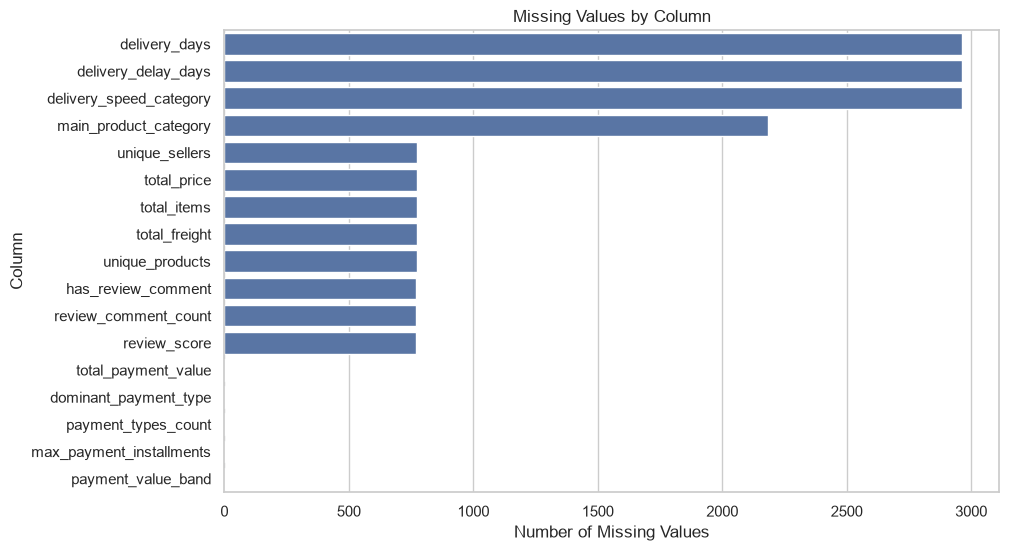

In [9]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

if len(missing_values) > 0:
    sns.barplot(x=missing_values.values, y=missing_values.index)
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.show()
else:
    print("No missing values found!")

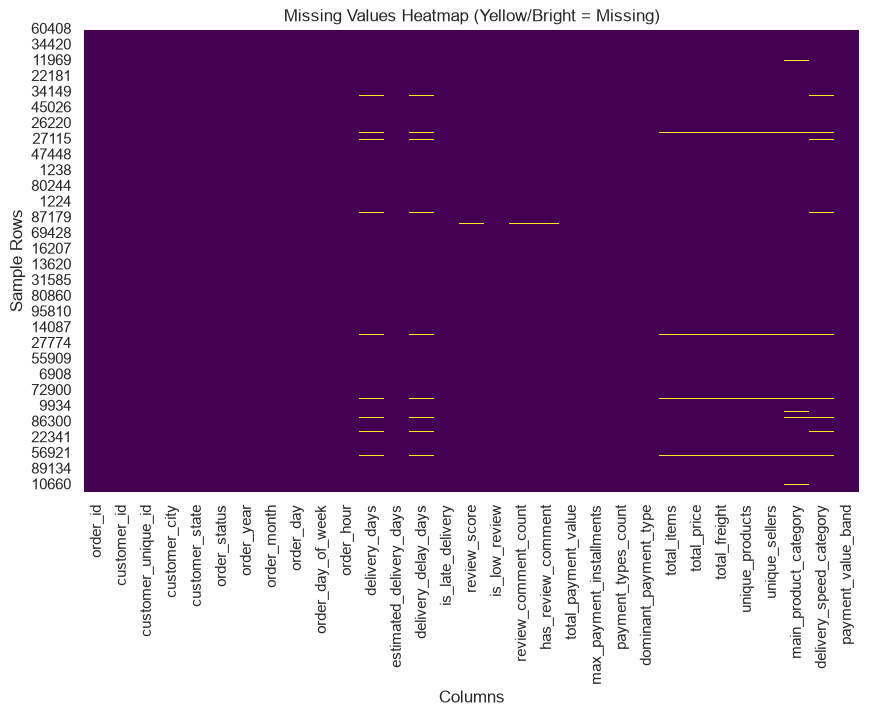

In [10]:
# Sample 1000 rows so the plot loads quickly
sns.heatmap(df.sample(min(1000, len(df))).isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap (Yellow/Bright = Missing)")
plt.xlabel("Columns")
plt.ylabel("Sample Rows")
plt.show()

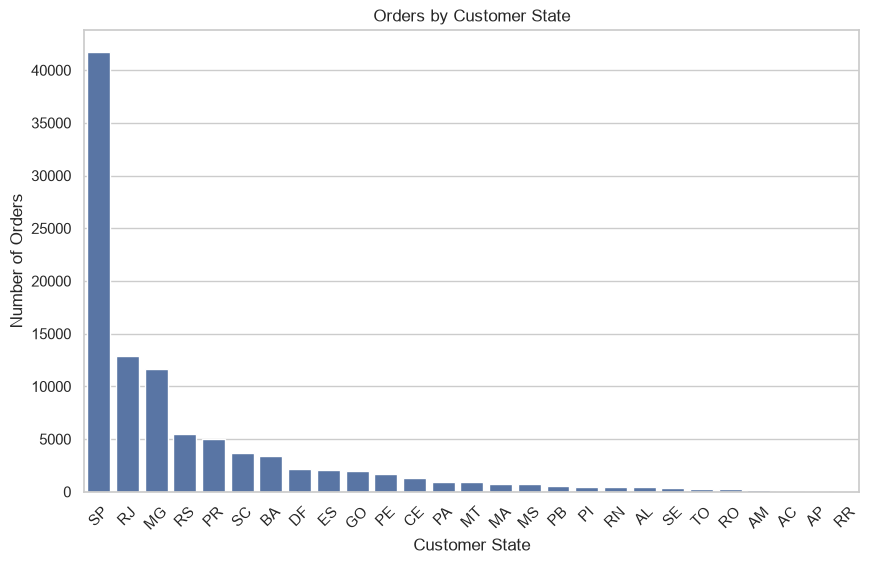

In [11]:
if "customer_state" in df.columns:
    sns.countplot(
        data=df, 
        x="customer_state", 
        order=df["customer_state"].value_counts().index
    )
    plt.title("Orders by Customer State")
    plt.xlabel("Customer State")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=45)
    plt.show()

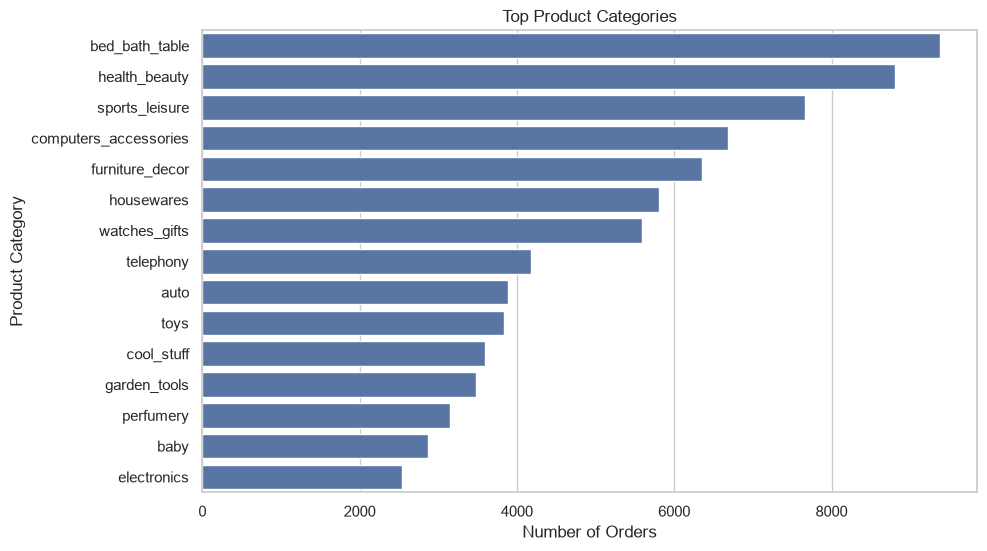

In [12]:
if "main_product_category" in df.columns:
    top_categories = df["main_product_category"].value_counts().head(15).index
    sns.countplot(
        data=df[df["main_product_category"].isin(top_categories)],
        y="main_product_category",
        order=top_categories
    )
    plt.title("Top Product Categories")
    plt.xlabel("Number of Orders")
    plt.ylabel("Product Category")
    plt.show()

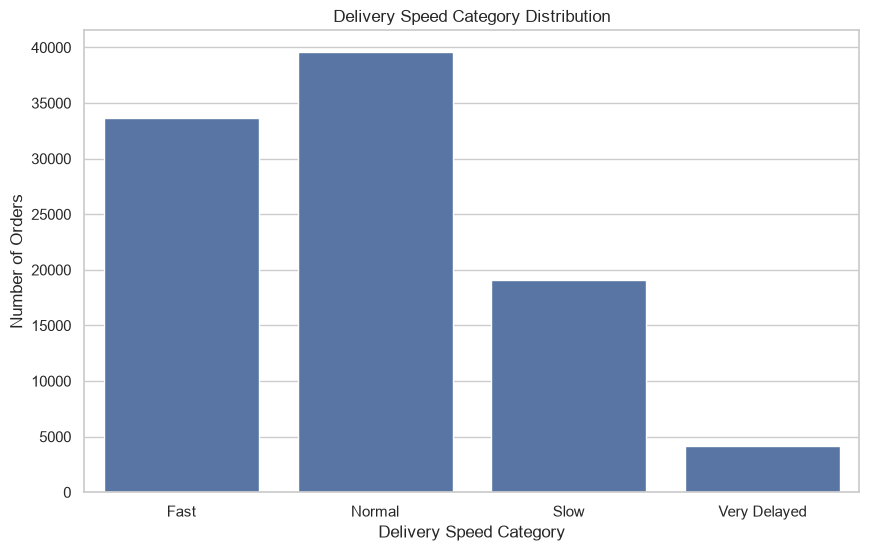

In [13]:
if "delivery_speed_category" in df.columns:
    delivery_order = ["Fast", "Normal", "Slow", "Very Delayed"]
    sns.countplot(
        data=df,
        x="delivery_speed_category",
        order=delivery_order
    )
    plt.title("Delivery Speed Category Distribution")
    plt.xlabel("Delivery Speed Category")
    plt.ylabel("Number of Orders")
    plt.show()

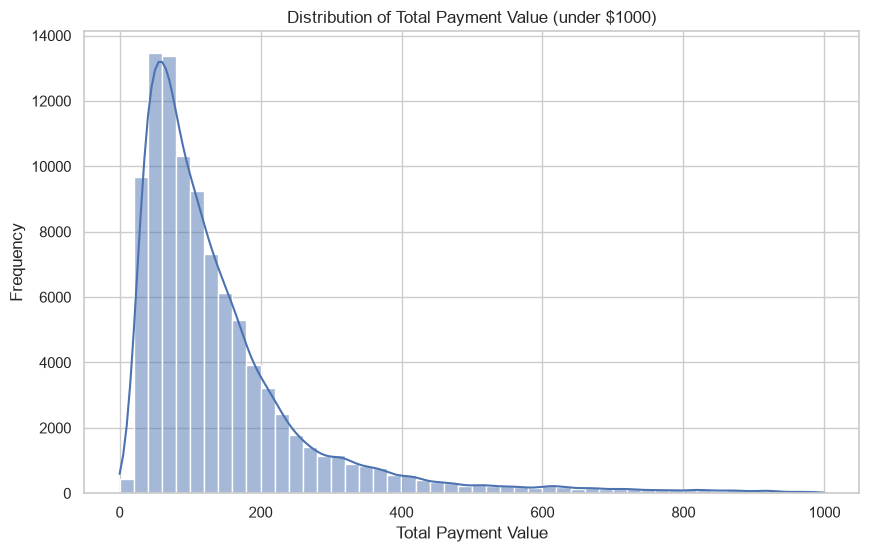

In [14]:
if "total_payment_value" in df.columns:
    # Filter under 1000 so the graph is readable
    sns.histplot(
        data=df[df["total_payment_value"] < 1000],
        x="total_payment_value",
        bins=50,
        kde=True
    )
    plt.title("Distribution of Total Payment Value (under $1000)")
    plt.xlabel("Total Payment Value")
    plt.ylabel("Frequency")
    plt.show()

Skewness Values:
 total_freight          12.052723
total_price             9.727741
total_payment_value     9.150169
total_items             7.527006
delivery_days           3.828790
delivery_delay_days     2.014360
dtype: float64


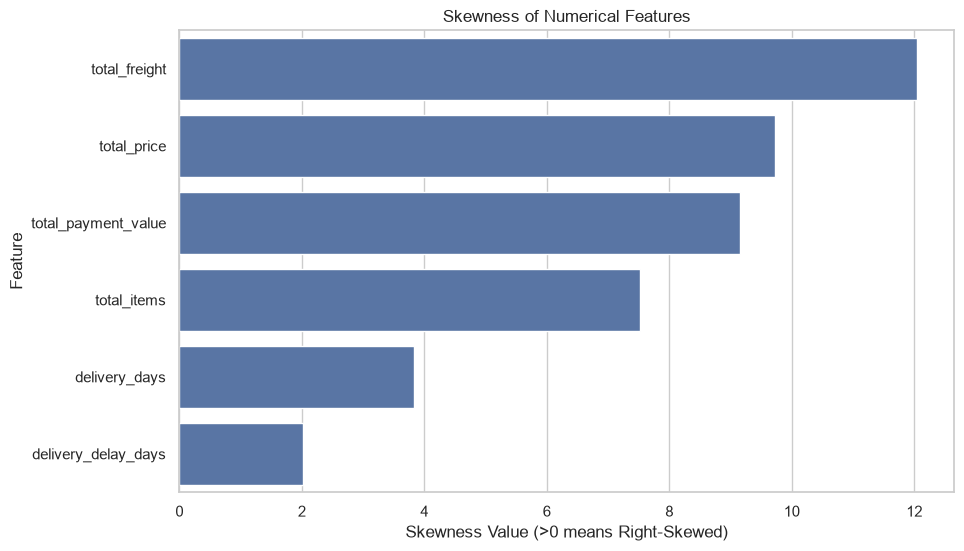

In [15]:
skew_cols = [
    "total_payment_value", "total_price", "total_freight", 
    "delivery_days", "delivery_delay_days", "total_items"
]
skew_cols = keep_existing_columns(df, skew_cols)

skewness_values = df[skew_cols].skew().sort_values(ascending=False)
print("Skewness Values:\n", skewness_values)

sns.barplot(x=skewness_values.values, y=skewness_values.index)
plt.title("Skewness of Numerical Features")
plt.xlabel("Skewness Value (>0 means Right-Skewed)")
plt.ylabel("Feature")
plt.show()

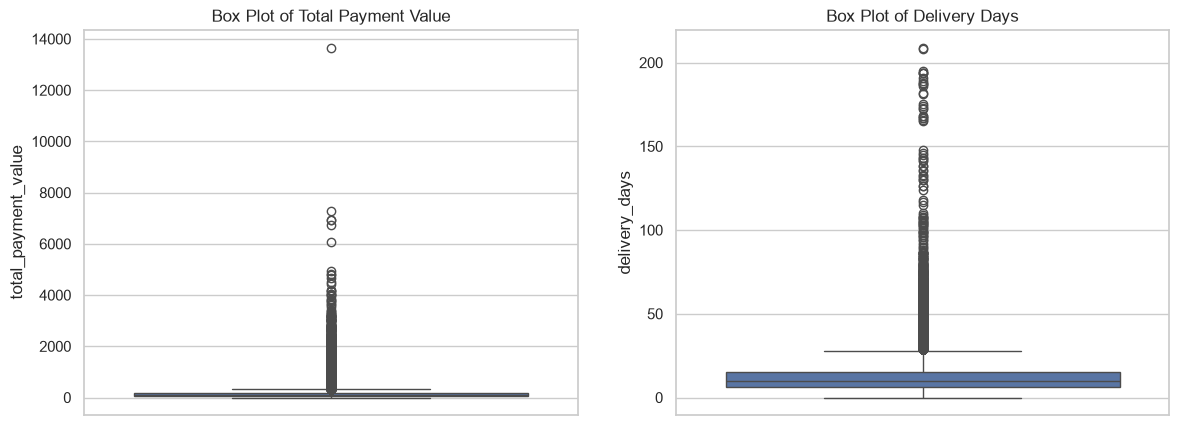

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if "total_payment_value" in df.columns:
    sns.boxplot(data=df, y="total_payment_value", ax=axes[0])
    axes[0].set_title("Box Plot of Total Payment Value")

if "delivery_days" in df.columns:
    sns.boxplot(data=df, y="delivery_days", ax=axes[1])
    axes[1].set_title("Box Plot of Delivery Days")

plt.show()

In [17]:
def iqr_outlier_summary(dataframe, column):
    q1 = dataframe[column].quantile(0.25)
    q3 = dataframe[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = dataframe[(dataframe[column] < lower_bound) | (dataframe[column] > upper_bound)]
    
    return {
        "column": column,
        "q1": round(q1, 2),
        "q3": round(q3, 2),
        "iqr": round(iqr, 2),
        "lower_bound": round(lower_bound, 2),
        "upper_bound": round(upper_bound, 2),
        "outlier_count": len(outliers),
        "outlier_percent": round((len(outliers) / len(dataframe)) * 100, 2)
    }

# Check outliers for payment value
if "total_payment_value" in df.columns:
    print(iqr_outlier_summary(df, "total_payment_value"))

# Check outliers for delivery days
if "delivery_days" in df.columns:
    print(iqr_outlier_summary(df, "delivery_days"))

{'column': 'total_payment_value', 'q1': np.float64(62.01), 'q3': np.float64(176.97), 'iqr': np.float64(114.96), 'lower_bound': np.float64(-110.43), 'upper_bound': np.float64(349.41), 'outlier_count': 7866, 'outlier_percent': 7.91}
{'column': 'delivery_days', 'q1': np.float64(6.0), 'q3': np.float64(15.0), 'iqr': np.float64(9.0), 'lower_bound': np.float64(-7.5), 'upper_bound': np.float64(28.5), 'outlier_count': 5025, 'outlier_percent': 5.05}


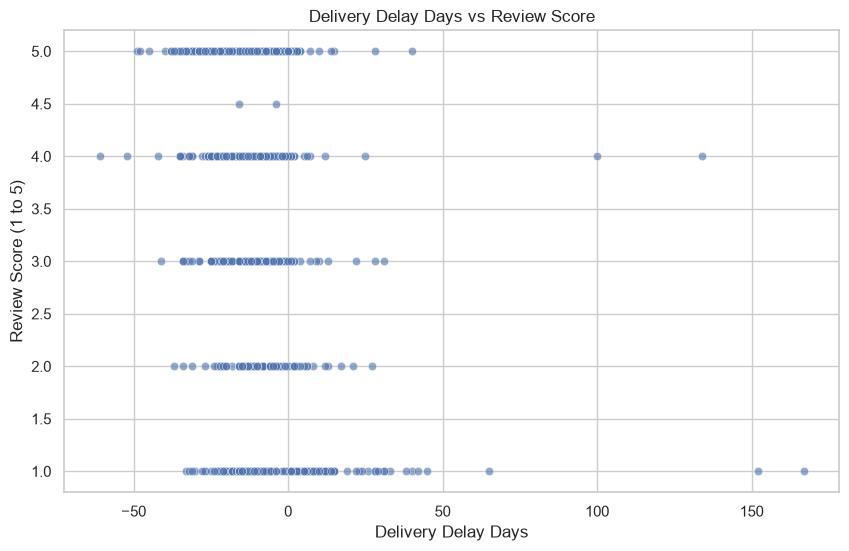

In [18]:
if {"delivery_delay_days", "review_score"}.issubset(df.columns):
    # Sample 2000 rows for neat plotting
    sns.scatterplot(
        data=df.sample(min(2000, len(df))),
        x="delivery_delay_days",
        y="review_score",
        alpha=0.6
    )
    plt.title("Delivery Delay Days vs Review Score")
    plt.xlabel("Delivery Delay Days")
    plt.ylabel("Review Score (1 to 5)")
    plt.show()

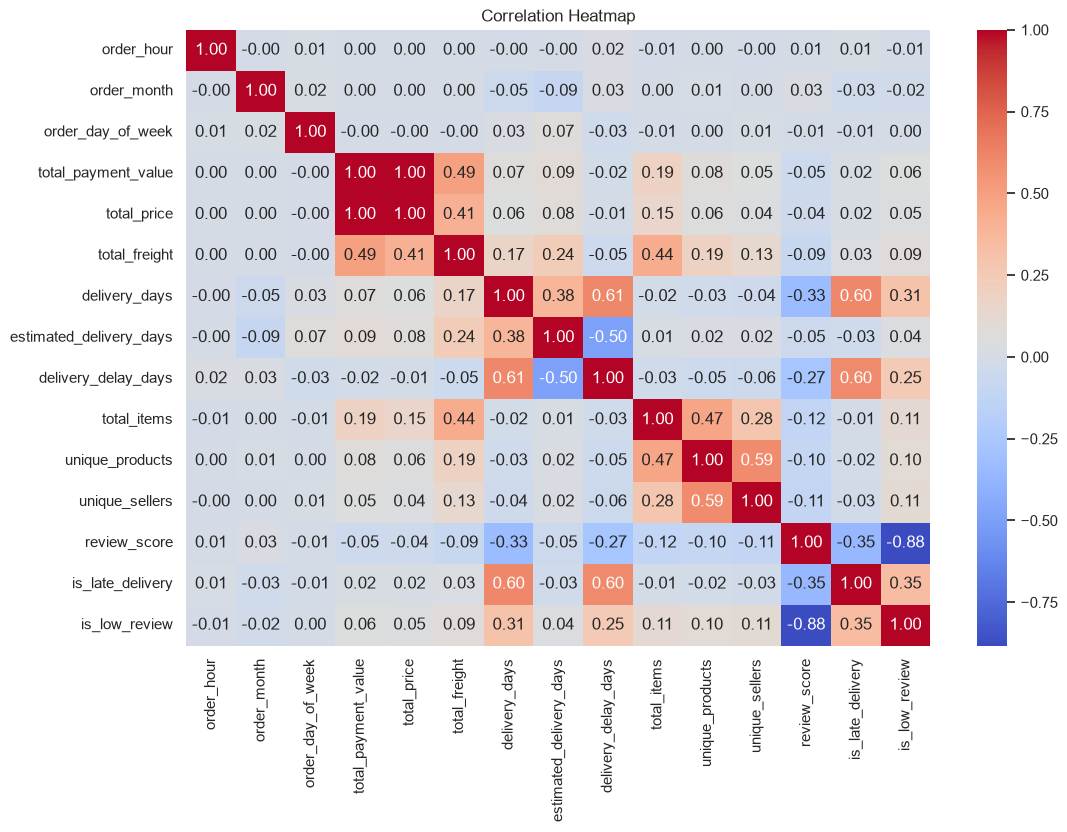

In [19]:
numeric_columns = [
    "order_hour", "order_month", "order_day_of_week",
    "total_payment_value", "total_price", "total_freight",
    "delivery_days", "estimated_delivery_days", "delivery_delay_days",
    "total_items", "unique_products", "unique_sellers",
    "review_score", "is_late_delivery", "is_low_review"
]
numeric_columns = keep_existing_columns(df, numeric_columns)

corr = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

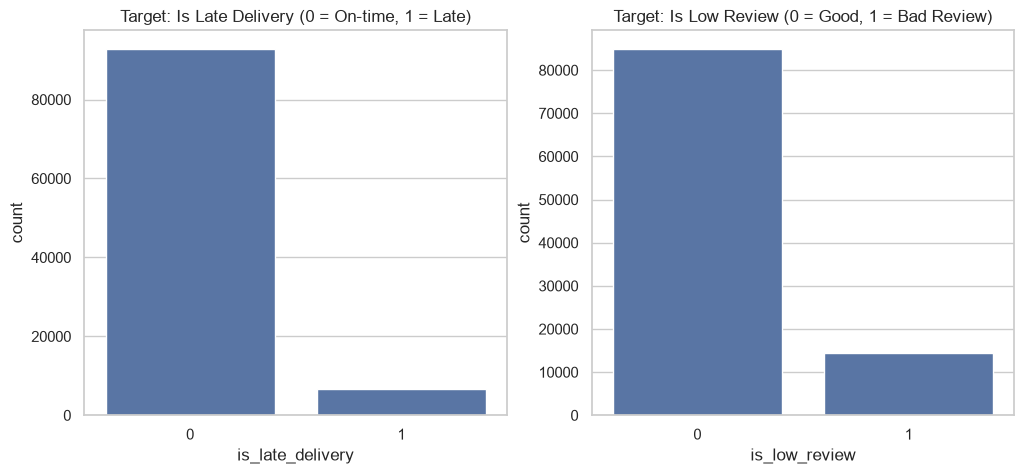

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

if "is_late_delivery" in df.columns:
    sns.countplot(data=df, x="is_late_delivery", ax=axes[0])
    axes[0].set_title("Target: Is Late Delivery (0 = On-time, 1 = Late)")

if "is_low_review" in df.columns:
    sns.countplot(data=df, x="is_low_review", ax=axes[1])
    axes[1].set_title("Target: Is Low Review (0 = Good, 1 = Bad Review)")

plt.show()

In [22]:
clean_df = df.copy()

# 1. Add missingness indicator for delivery days
if "delivery_days" in clean_df.columns:
    clean_df["missing_delivery_days"] = clean_df["delivery_days"].isnull().astype(int)

# 2. Fill categorical missing values with 'Unknown'
categorical_missing_cols = [
    "main_product_category", "dominant_payment_type", 
    "delivery_speed_category", "payment_value_band", 
    "customer_state", "customer_city", "order_status"
]
categorical_missing_cols = keep_existing_columns(clean_df, categorical_missing_cols)

for col in categorical_missing_cols:
    # If it has a strict category list, convert it to standard text first
    if str(clean_df[col].dtype) == "category":
        clean_df[col] = clean_df[col].astype(object)
    clean_df[col] = clean_df[col].fillna("Unknown")

# 3. Fill numerical missing values with Median
numerical_missing_cols = [
    "total_payment_value", "total_price", "total_freight", 
    "delivery_days", "estimated_delivery_days", "delivery_delay_days", 
    "review_score", "total_items", "unique_products", "unique_sellers",
    "review_comment_count", "has_review_comment", "payment_types_count", "max_payment_installments"
]
numerical_missing_cols = keep_existing_columns(clean_df, numerical_missing_cols)

for col in numerical_missing_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

print("Missing values left in dataset:", clean_df.isnull().sum().sum())
print("Success! All blanks have been safely filled.")

Missing values left in dataset: 0
Success! All blanks have been safely filled.


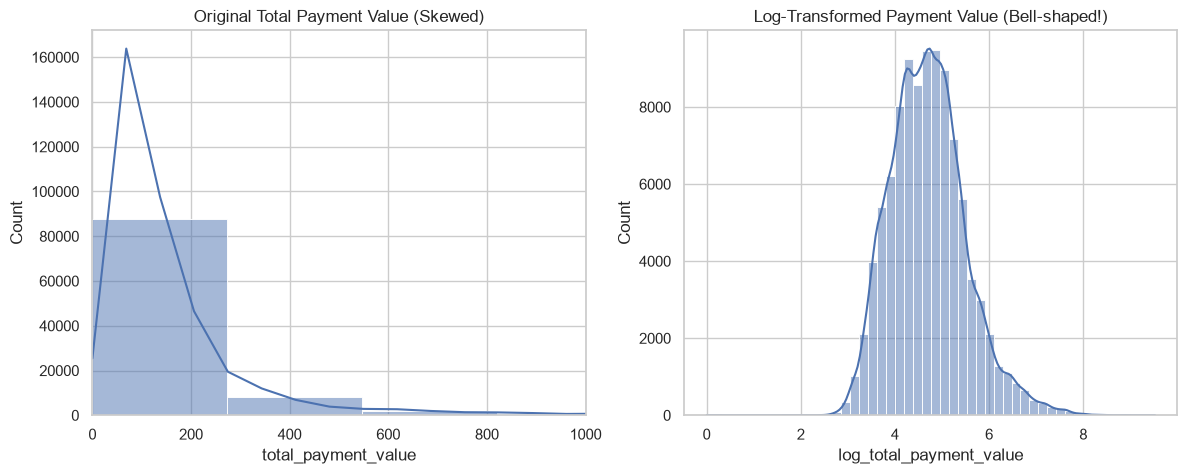

In [23]:
if "total_payment_value" in clean_df.columns:
    clean_df["log_total_payment_value"] = np.log1p(clean_df["total_payment_value"])

if "total_freight" in clean_df.columns:
    clean_df["log_total_freight"] = np.log1p(clean_df["total_freight"])

if "total_price" in clean_df.columns:
    clean_df["log_total_price"] = np.log1p(clean_df["total_price"])

# Compare Original vs Log-Transformed
if {"total_payment_value", "log_total_payment_value"}.issubset(clean_df.columns):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sns.histplot(data=clean_df, x="total_payment_value", bins=50, kde=True, ax=axes[0])
    axes[0].set_title("Original Total Payment Value (Skewed)")
    axes[0].set_xlim(0, 1000)
    
    sns.histplot(data=clean_df, x="log_total_payment_value", bins=50, kde=True, ax=axes[1])
    axes[1].set_title("Log-Transformed Payment Value (Bell-shaped!)")
    
    plt.show()

In [25]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.2 MB 3.6 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.2 MB 3.5 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.2 MB 3.9 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 3.9 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/8.2 MB 3.8 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.2 MB 3.6 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.2 MB 3.7 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.2 MB 3.9 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 3.8 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 3.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   - --------------------


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

scaling_cols = [
    "total_payment_value",
    "total_price",
    "total_freight",
    "delivery_days",
    "total_items"
]
scaling_cols = keep_existing_columns(clean_df, scaling_cols)

# Initialize the three scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

# Fit and transform the columns
standard_scaled = standard_scaler.fit_transform(clean_df[scaling_cols])
minmax_scaled = minmax_scaler.fit_transform(clean_df[scaling_cols])
robust_scaled = robust_scaler.fit_transform(clean_df[scaling_cols])

# Create DataFrames with clear column names
standard_scaled_df = pd.DataFrame(
    standard_scaled,
    columns=[col + "_standard_scaled" for col in scaling_cols]
)
minmax_scaled_df = pd.DataFrame(
    minmax_scaled,
    columns=[col + "_minmax_scaled" for col in scaling_cols]
)
robust_scaled_df = pd.DataFrame(
    robust_scaled,
    columns=[col + "_robust_scaled" for col in scaling_cols]
)

print("Scaling completed successfully!")
print("Standard Scaled Preview (Centered at 0):")
standard_scaled_df.head()

Scaling completed successfully!
Standard Scaled Preview (Centered at 0):


,total_payment_value_standard_scaled,total_price_standard_scaled,total_freight_standard_scaled,delivery_days_standard_scaled,total_items_standard_scaled
0,-0.550936,-0.511593,-0.651748,-0.428217,-0.262121
1,-0.087992,-0.088902,-0.000904,0.102853,-0.262121
2,0.081687,0.107411,-0.165006,-0.322003,-0.262121
3,-0.400045,-0.440073,0.204918,0.102853,-0.262121
4,-0.596397,-0.559671,-0.651748,-1.065501,-0.262121


In [27]:
leakage_columns = [
    "delivery_delay_days",
    "delivery_speed_category"
]

print("Columns that cause Data Leakage for predicting late delivery:")
for col in leakage_columns:
    print(f" - {col}")

print("\nKey rule: Never use information that is only known AFTER delivery occurs!")

Columns that cause Data Leakage for predicting late delivery:
 - delivery_delay_days
 - delivery_speed_category

Key rule: Never use information that is only known AFTER delivery occurs!


In [28]:
import os

# Ensure folder exists
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# Save the file
save_path = "../data/processed/olist_orders_abt_cleaned.csv"
try:
    clean_df.to_csv(save_path, index=False)
except Exception:
    save_path = "data/processed/olist_orders_abt_cleaned.csv"
    clean_df.to_csv(save_path, index=False)

print(f"Cleaned ABT saved successfully to: {save_path}")
print("Final Cleaned Shape (Rows, Columns):", clean_df.shape)

Cleaned ABT saved successfully to: ../data/processed/olist_orders_abt_cleaned.csv
Final Cleaned Shape (Rows, Columns): (99441, 35)
